In [20]:
import matplotlib.pyplot as plt

In [2]:
import torch
from torch.utils.data import DataLoader 
from torchvision import transforms
from medmnist import DermaMNIST

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
])

In [4]:
train_dataset = DermaMNIST(split='train', download=True,size=64, transform=transform)

In [5]:
dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [6]:
images, labels = next(iter(dataloader))
print(images.shape)  

torch.Size([64, 3, 64, 64])


In [7]:
import torch.nn as nn

class Generator(nn.Module):                                    #defining a new network called Generator
    def __init__(self):                                        #setup function
        super().__init__()                                      #required boilerplate for PyTorch networks
        self.main = nn.Sequential(                               #stack of layers (running in order)
            nn.ConvTranspose2d(100, 512, 4, 1, 0, bias=False),   #turning random noise into a 4x4 feature map
            nn.BatchNorm2d(512),                                 #stabilizing training
            nn.ReLU(True),                                       #activation function

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),   #from 4x4 to 8x8
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),   #from 8x8 to 16x16
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),    #from 16x16 to 32x32
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),      #from 32x32 to 64x64, outputs 3 color channels
            nn.Tanh()                                            # squashing output to [-1, 1] range (matches our normalized real images)
        )

    def forward(self, x):                                        #defining how data flows through the network
        return self.main(x)

In [8]:
class Discriminator(nn.Module):                                 #defining the Discriminator network
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),               #64x64 image to 32x32
            nn.LeakyReLU(0.2, inplace=True),                     #activation (allows small negative values through)

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),             #32x32 to 16x16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),            #16x16 to 8x8
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),            #8x8 to 4x4
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 0, bias=False),              #4x4 to single number (real vs fake score)
            nn.Sigmoid()                                          #squashing that number to between 0 and 1 (proba)
        )

    def forward(self, x):
        return self.main(x).view(-1, 1).squeeze(1)              #flattening output into a simple list of scores(1per image)

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [21]:
netG = Generator().to(device)
netD = Discriminator().to(device)

In [11]:
criterion = nn.BCELoss()  

In [12]:
optimizerD = torch.optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = torch.optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [17]:
fixed_noise = torch.randn(16, latent_dim, 1, 1, device=device)

In [14]:
num_epochs = 1
latent_dim = 100

for epoch in range(num_epochs):                                      #loop over the whole dataset this many times
    for i, (real_images, _) in enumerate(dataloader):                 #loop over each batch 
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        #Train Discriminator on real images
        netD.zero_grad()                                              #clear old gradients
        labels_real = torch.full((batch_size,), 1.0, device=device)   
        output_real = netD(real_images)
        lossD_real = criterion(output_real, labels_real)

        #Train Discriminator on fake images 
        noise = torch.randn(batch_size, latent_dim, 1, 1, device=device)  #random noise input for the Generator
        fake_images = netG(noise)                                     #Generator creates fake images from noise
        labels_fake = torch.full((batch_size,), 0.0, device=device)   
        output_fake = netD(fake_images.detach())                      #detach:dont update Generator here
        lossD_fake = criterion(output_fake, labels_fake)

        lossD = lossD_real + lossD_fake                                #total Discriminator loss
        lossD.backward()
        optimizerD.step()                                              #Discriminator learns

        #Train Generator
        netG.zero_grad()
        labels_gen = torch.full((batch_size,), 1.0, device=device)    #Generator wants Discriminator to say "real" 
        output = netD(fake_images)
        lossG = criterion(output, labels_gen)
        lossG.backward()
        optimizerG.step()                                              #Generator learns

    print(f"Epoch {epoch+1}/{num_epochs}  Loss D: {lossD.item():.4f}  Loss G: {lossG.item():.4f}")

Epoch 1/1  Loss D: 0.0063  Loss G: 7.4104


In [15]:
num_epochs = 1
latent_dim = 100

for epoch in range(num_epochs):
    for i, (real_images, _) in enumerate(dataloader):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        netD.zero_grad()
        labels_real = torch.full((batch_size,), 0.9, device=device)   #changed from 1.0 to 0.9 (label smoothing)
        output_real = netD(real_images)
        lossD_real = criterion(output_real, labels_real)

        noise = torch.randn(batch_size, latent_dim, 1, 1, device=device)
        fake_images = netG(noise)
        labels_fake = torch.full((batch_size,), 0.0, device=device)
        output_fake = netD(fake_images.detach())
        lossD_fake = criterion(output_fake, labels_fake)

        lossD = lossD_real + lossD_fake
        lossD.backward()
        optimizerD.step()

        netG.zero_grad()
        labels_gen = torch.full((batch_size,), 1.0, device=device)
        output = netD(fake_images)
        lossG = criterion(output, labels_gen)
        lossG.backward()
        optimizerG.step()

    print(f"Epoch {epoch+1}/{num_epochs}  Loss D: {lossD.item():.4f}  Loss G: {lossG.item():.4f}")

Epoch 1/1  Loss D: 0.3352  Loss G: 6.8357


Epoch 1/20  Loss D: 1.3267  Loss G: 0.7003
Epoch 2/20  Loss D: 1.3886  Loss G: 0.6217
Epoch 3/20  Loss D: 1.3517  Loss G: 0.6834
Epoch 4/20  Loss D: 1.3954  Loss G: 0.6401
Epoch 5/20  Loss D: 1.3555  Loss G: 0.6745


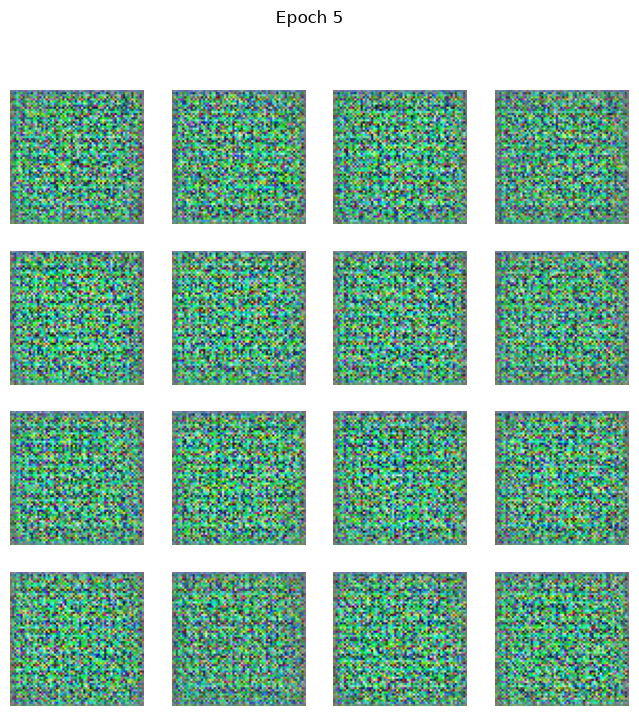

Epoch 6/20  Loss D: 1.3490  Loss G: 0.6653
Epoch 7/20  Loss D: 1.3794  Loss G: 0.6354
Epoch 8/20  Loss D: 1.4024  Loss G: 0.6418
Epoch 9/20  Loss D: 1.4094  Loss G: 0.6204
Epoch 10/20  Loss D: 1.3267  Loss G: 0.6785


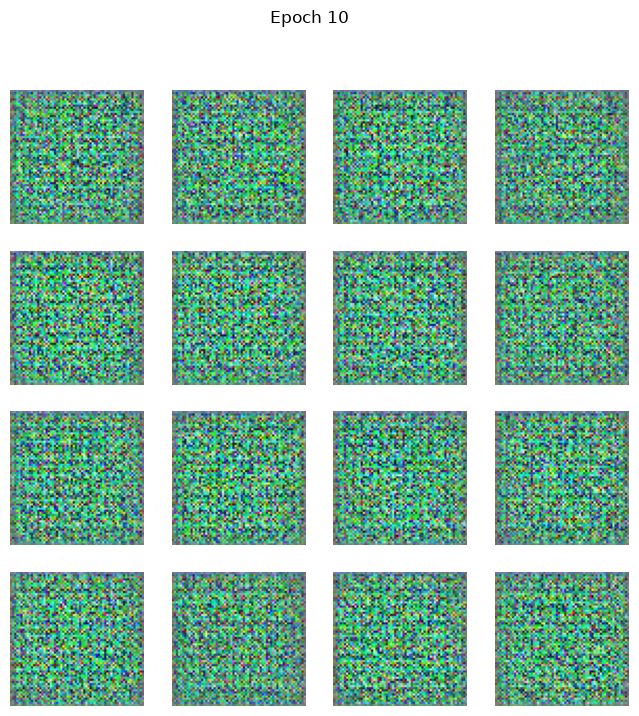

Epoch 11/20  Loss D: 1.3939  Loss G: 0.6493
Epoch 12/20  Loss D: 1.4022  Loss G: 0.6115
Epoch 13/20  Loss D: 1.4491  Loss G: 0.6040
Epoch 14/20  Loss D: 1.3562  Loss G: 0.6547
Epoch 15/20  Loss D: 1.3672  Loss G: 0.6674


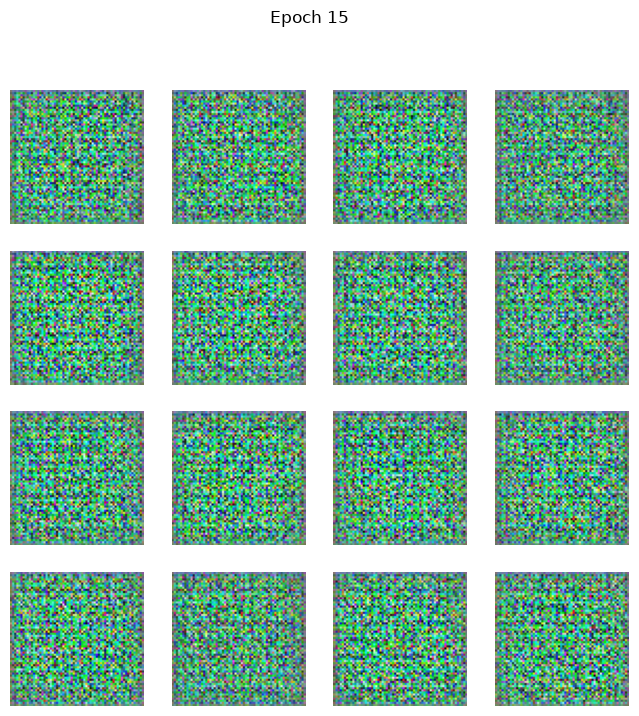

Epoch 16/20  Loss D: 1.3946  Loss G: 0.6138
Epoch 17/20  Loss D: 1.3525  Loss G: 0.6465
Epoch 18/20  Loss D: 1.3744  Loss G: 0.6662
Epoch 19/20  Loss D: 1.4163  Loss G: 0.6129
Epoch 20/20  Loss D: 1.3405  Loss G: 0.6744


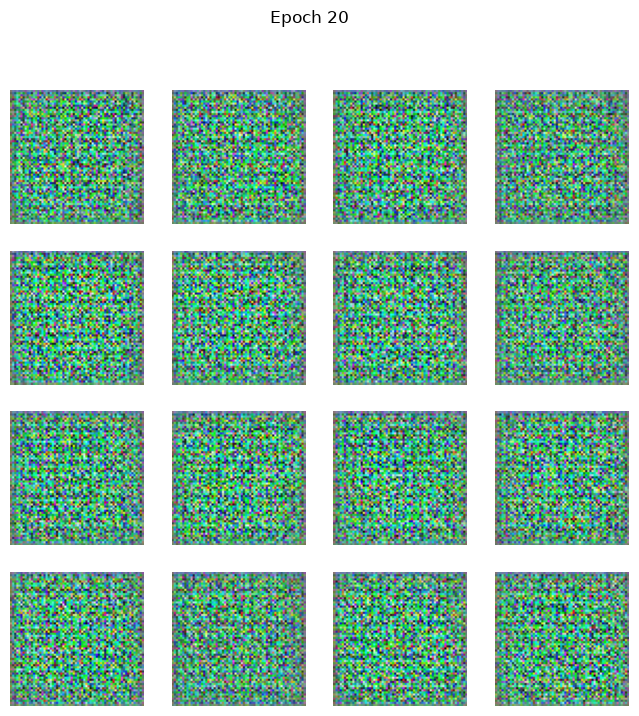

In [22]:
num_epochs = 20

for epoch in range(num_epochs):
    for i, (real_images, _) in enumerate(dataloader):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        netD.zero_grad()
        labels_real = torch.full((batch_size,), 0.9, device=device)
        output_real = netD(real_images)
        lossD_real = criterion(output_real, labels_real)

        noise = torch.randn(batch_size, latent_dim, 1, 1, device=device)
        fake_images = netG(noise)
        labels_fake = torch.full((batch_size,), 0.0, device=device)
        output_fake = netD(fake_images.detach())
        lossD_fake = criterion(output_fake, labels_fake)

        lossD = lossD_real + lossD_fake
        lossD.backward()
        optimizerD.step()

        netG.zero_grad()
        labels_gen = torch.full((batch_size,), 1.0, device=device)
        output = netD(fake_images)
        lossG = criterion(output, labels_gen)
        lossG.backward()
        optimizerG.step()

    print(f"Epoch {epoch+1}/{num_epochs}  Loss D: {lossD.item():.4f}  Loss G: {lossG.item():.4f}")

    if (epoch + 1) % 5 == 0:                                    #every 5 epochs,show generated samples
        with torch.no_grad():
            samples = netG(fixed_noise).detach().cpu()
        samples = (samples + 1) / 2                             #un-normalize from [-1,1] back to [0,1] for display
        fig, axes = plt.subplots(4, 4, figsize=(8, 8))
        for idx, ax in enumerate(axes.flatten()):
            ax.imshow(samples[idx].permute(1, 2, 0))
            ax.axis('off')
        plt.suptitle(f"Epoch {epoch+1}")
        plt.show()

Epoch 1/40  Loss D: 1.4271  Loss G: 0.6063
Epoch 2/40  Loss D: 1.3448  Loss G: 0.6692
Epoch 3/40  Loss D: 1.3902  Loss G: 0.6699
Epoch 4/40  Loss D: 1.3553  Loss G: 0.6568
Epoch 5/40  Loss D: 1.4157  Loss G: 0.6098


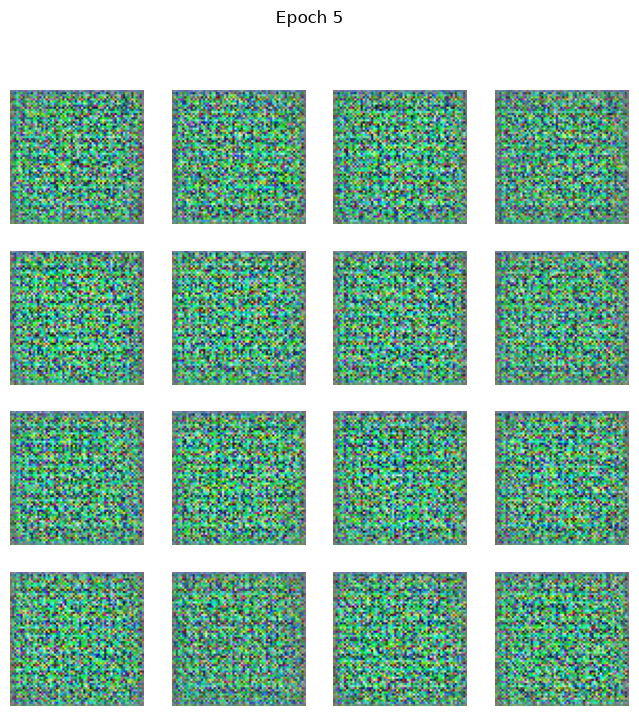

Epoch 6/40  Loss D: 1.3885  Loss G: 0.6116
Epoch 7/40  Loss D: 1.5070  Loss G: 0.5800
Epoch 8/40  Loss D: 1.3624  Loss G: 0.6542
Epoch 9/40  Loss D: 1.3865  Loss G: 0.6243
Epoch 10/40  Loss D: 1.4510  Loss G: 0.5991


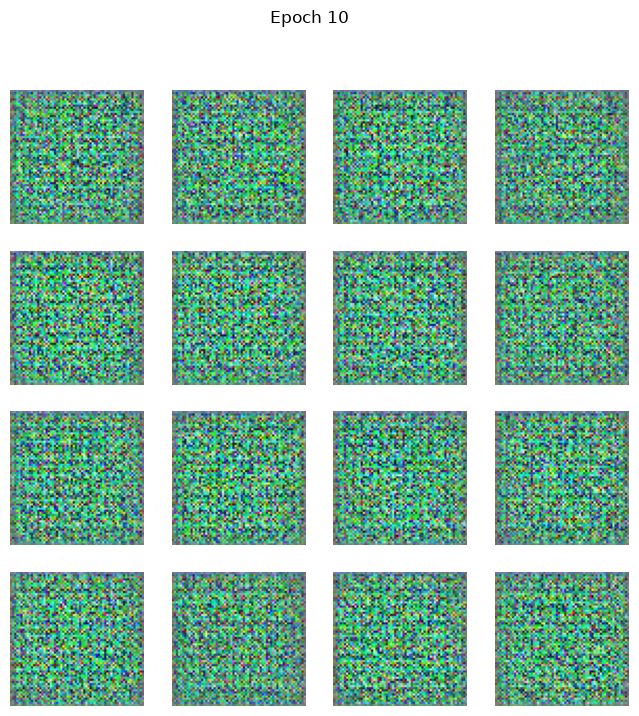

Epoch 11/40  Loss D: 1.4691  Loss G: 0.5612
Epoch 12/40  Loss D: 1.3797  Loss G: 0.6292
Epoch 13/40  Loss D: 1.4213  Loss G: 0.6106
Epoch 14/40  Loss D: 1.4261  Loss G: 0.6091
Epoch 15/40  Loss D: 1.3875  Loss G: 0.6254


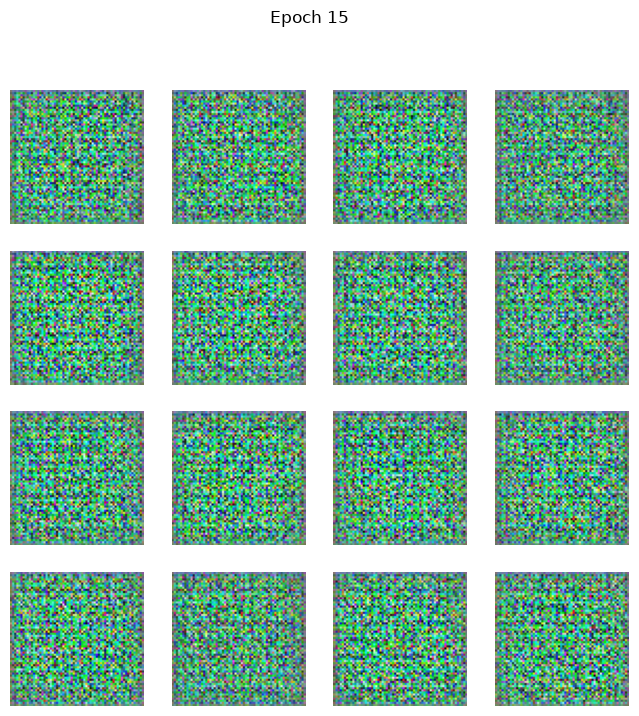

Epoch 16/40  Loss D: 1.4366  Loss G: 0.6207
Epoch 17/40  Loss D: 1.3803  Loss G: 0.6385
Epoch 18/40  Loss D: 1.4672  Loss G: 0.6115


In [ ]:
num_epochs = 40
for epoch in range(num_epochs):
    for i, (real_images, _) in enumerate(dataloader):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)
        netD.zero_grad()
        labels_real = torch.full((batch_size,), 0.9, device=device)
        output_real = netD(real_images)
        lossD_real = criterion(output_real, labels_real)
        noise = torch.randn(batch_size, latent_dim, 1, 1, device=device)
        fake_images = netG(noise)
        labels_fake = torch.full((batch_size,), 0.0, device=device)
        output_fake = netD(fake_images.detach())
        lossD_fake = criterion(output_fake, labels_fake)
        lossD = lossD_real + lossD_fake
        lossD.backward()
        optimizerD.step()
        netG.zero_grad()
        labels_gen = torch.full((batch_size,), 1.0, device=device)
        output = netD(fake_images)
        lossG = criterion(output, labels_gen)
        lossG.backward()
        optimizerG.step()
    print(f"Epoch {epoch+1}/{num_epochs}  Loss D: {lossD.item():.4f}  Loss G: {lossG.item():.4f}")
    if (epoch + 1) % 5 == 0:
        with torch.no_grad():
            samples = netG(fixed_noise).detach().cpu()
        samples = (samples + 1) / 2
        fig, axes = plt.subplots(4, 4, figsize=(8, 8))
        for idx, ax in enumerate(axes.flatten()):
            ax.imshow(samples[idx].permute(1, 2, 0))
            ax.axis('off')
        plt.suptitle(f"Epoch {epoch+1}")
        plt.show()